# Lab 6: Leaky Integrate-and-Fire Neuron and Spike-Timing-Dependent Plasticity

**Name:** Anson Dias

**Objectives**

1. Implement the leaky integrate-and-fire (LIF) differential equation in Python with the
   forward Euler method and a time step of $\Delta t = 1$ ms.
2. Simulate 500 ms of activity at three input current levels, plot membrane voltage against
   time and mark every spike.
3. Compute the firing rate as a function of input current and plot the frequency-input
   (F-I) curve.
4. Implement a two-neuron (pre → post) pair with an STDP learning rule whose window is an
   exponential decay with separate time constants for potentiation and depression.
5. Run 1000 trials with relative spike timing drawn from $\mathcal{U}(-50, +50)$ ms, plot the
   mean synaptic weight change against the spike timing difference, and check that the
   result reproduces the asymmetric STDP window.

The notebook runs top to bottom in a few seconds and needs only `numpy` and `matplotlib`.
Every figure is also saved as a PNG in a `figures/` folder next to the notebook.

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DT = 1.0          # simulation time step (ms), fixed by the lab
SEED = 6          # random seed for the STDP trials, so results are reproducible
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Plot styling: light grid, no top/right spines, a small fixed colour set.
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 10.5,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "lines.linewidth": 1.5,
})

## Part 1: The leaky integrate-and-fire neuron

### Model

Below threshold, the membrane behaves like an RC circuit driven by an injected current $I(t)$:

$$\tau_m \frac{dV}{dt} = -\big(V - E_L\big) + R_m I(t)$$

When $V$ reaches the threshold $V_{th}$ the neuron emits a spike. $V$ is then reset to
$V_{reset}$ and held there for an absolute refractory period $t_{ref}$.

### Euler discretisation ($\Delta t = 1$ ms)

$$V_{n+1} = V_n + \frac{\Delta t}{\tau_m}\Big[-\big(V_n - E_L\big) + R_m I_n\Big]$$

If $V_{n+1} \ge V_{th}$, a spike is recorded at $t_{n+1}$ and $V_{n+1} \leftarrow V_{reset}$.
The next $t_{ref}/\Delta t$ steps are clamped at $V_{reset}$. Because
$\Delta t / \tau_m = 0.1 \ll 2$, the Euler update is numerically stable.

### Parameters

| Symbol | Meaning | Value |
|---|---|---|
| $\tau_m$ | membrane time constant | 10 ms |
| $E_L$ | leak (resting) potential | −65 mV |
| $V_{th}$ | spike threshold | −50 mV |
| $V_{reset}$ | reset potential | −65 mV |
| $R_m$ | membrane resistance | 10 MΩ |
| $t_{ref}$ | absolute refractory period | 2 ms |

Units: mV, ms, nA and MΩ, so $R_m I$ comes out in mV (10 MΩ × 1 nA = 10 mV).
Under a constant current the voltage relaxes toward $V_\infty = E_L + R_m I$, so the
neuron can only fire if $V_\infty > V_{th}$. That gives the **rheobase**
$I_{rh} = (V_{th} - E_L)/R_m = 1.5$ nA.

In [2]:
@dataclass(frozen=True)
class LIFParams:
    tau_m: float = 10.0     # ms
    e_l: float = -65.0      # mV
    v_th: float = -50.0     # mV
    v_reset: float = -65.0  # mV
    r_m: float = 10.0       # MOhm
    t_ref: float = 2.0      # ms


LIF = LIFParams()


class LIFNeuron:
    """A single LIF neuron advanced one forward-Euler step at a time."""

    def __init__(self, params=LIF, dt=DT):
        self.p = params
        self.dt = dt
        self.v = params.e_l
        self.ref_steps = int(round(params.t_ref / dt))
        self.ref_left = 0

    def step(self, i_ext):
        """Advance from t_n to t_n + dt with input current i_ext (nA). Returns True on a spike."""
        p = self.p
        if self.ref_left > 0:  # absolute refractory period: hold at reset, no integration
            self.ref_left -= 1
            self.v = p.v_reset
            return False
        v_next = self.v + self.dt / p.tau_m * (-(self.v - p.e_l) + p.r_m * i_ext)
        if v_next >= p.v_th:
            self.v = p.v_reset
            self.ref_left = self.ref_steps
            return True
        self.v = v_next
        return False


def simulate_lif(i_ext, duration=500.0, params=LIF, dt=DT):
    """Simulate one LIF neuron under a constant (scalar) or time-varying (array) current.

    Returns (t, v, spike_times): times in ms, voltages in mV and spike times in ms.
    """
    n_steps = int(round(duration / dt))
    current = np.broadcast_to(np.asarray(i_ext, dtype=float), (n_steps,))
    neuron = LIFNeuron(params, dt)
    t = np.arange(n_steps + 1) * dt
    v = np.empty(n_steps + 1)
    v[0] = neuron.v
    spikes = []
    for n in range(n_steps):
        if neuron.step(current[n]):
            spikes.append(t[n + 1])
        v[n + 1] = neuron.v
    return t, v, np.array(spikes)


def firing_rate(spike_times, duration):
    """Mean firing rate in Hz: spike count divided by the simulated time (ms -> s)."""
    return len(spike_times) / (duration / 1000.0)


def lif_rate_theory(i_ext, params=LIF):
    """Firing rate (Hz) of the continuous-time LIF model, for comparison with the Euler result.

    Under constant input, the time from reset to threshold is
    tau_m * ln[(V_inf - V_reset) / (V_inf - V_th)] with V_inf = E_L + R_m I,
    so the rate is 1 / (t_ref + that time).
    """
    i_ext = np.atleast_1d(np.asarray(i_ext, dtype=float))
    v_inf = params.e_l + params.r_m * i_ext
    rate = np.zeros_like(v_inf)
    fires = v_inf > params.v_th
    isi = params.t_ref + params.tau_m * np.log(
        (v_inf[fires] - params.v_reset) / (v_inf[fires] - params.v_th))
    rate[fires] = 1000.0 / isi
    return rate

### 1a. Membrane voltage at three input current levels (500 ms each)

I use three currents above the 1.5 nA rheobase: one just above it (1.6 nA), one moderate
(2.0 nA) and one strong (3.0 nA). The model has no spike waveform; $V$ simply jumps from
just below threshold back to $V_{reset}$. To make each spike visible, it is drawn as a
vertical line from $V_{th}$ up to +20 mV and marked with an orange dot. This is only a
display convention and does not affect the simulation.

 I (nA)  V_inf (mV)  spikes  rate (Hz)  first spike (ms)  ISI (ms)
    1.6       -49.0      17       34.0                27      29.0
    2.0       -45.0      31       62.0                14      16.0
    3.0       -35.0      55      110.0                 7       9.0


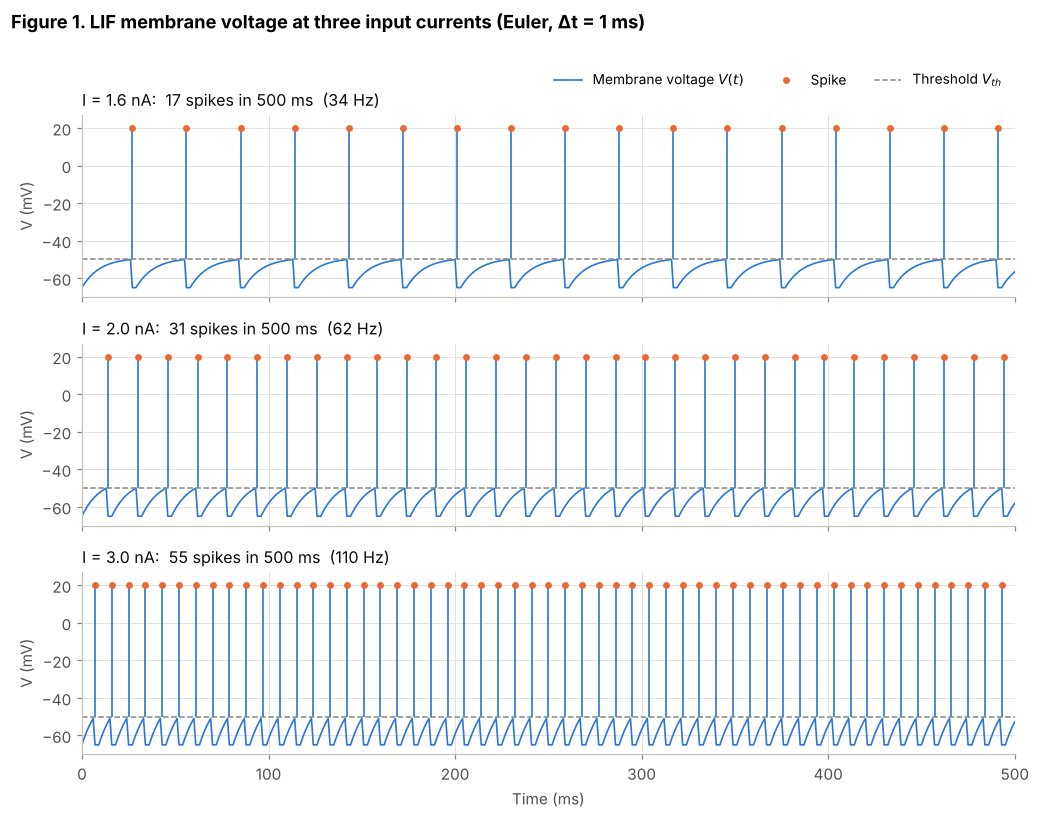

In [3]:
DURATION = 500.0                       # ms
CURRENTS = (1.6, 2.0, 3.0)             # nA
V_PEAK = 20.0                          # mV, height of the drawn spike (display only)

runs = {i: simulate_lif(i, DURATION) for i in CURRENTS}

print(f"{'I (nA)':>7} {'V_inf (mV)':>11} {'spikes':>7} {'rate (Hz)':>10} {'first spike (ms)':>17} {'ISI (ms)':>9}")
for i, (t, v, spk) in runs.items():
    v_inf = LIF.e_l + LIF.r_m * i
    isi = np.diff(spk)
    print(f"{i:7.1f} {v_inf:11.1f} {len(spk):7d} {firing_rate(spk, DURATION):10.1f} "
          f"{spk[0]:17.0f} {isi.mean():9.1f}")

fig, axes = plt.subplots(len(CURRENTS), 1, figsize=(9.5, 7.4), sharex=True, sharey=True)
for ax, (i, (t, v, spk)) in zip(axes, runs.items()):
    ax.plot(t, v, color=BLUE, lw=1.1, label="Membrane voltage $V(t)$")
    ax.vlines(spk, LIF.v_th, V_PEAK, color=BLUE, lw=1.1)
    ax.plot(spk, np.full(len(spk), V_PEAK), "o", ms=3.5, color=ORANGE, label="Spike")
    ax.axhline(LIF.v_th, ls="--", lw=1, color=MUTED, label="Threshold $V_{th}$")
    ax.set_title(f"I = {i:.1f} nA:  {len(spk)} spikes in 500 ms  ({firing_rate(spk, DURATION):.0f} Hz)")
    ax.set_ylabel("V (mV)")
    ax.set_ylim(-70, 27)
axes[0].legend(loc="lower right", ncols=3, bbox_to_anchor=(1, 1.08))
axes[-1].set_xlabel("Time (ms)")
axes[-1].set_xlim(0, DURATION)
fig.suptitle("Figure 1. LIF membrane voltage at three input currents (Euler, Δt = 1 ms)",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_lif_voltage_traces.png")
plt.show()

**Observations.** At every current the voltage rises along a saturating exponential toward
$V_\infty = E_L + R_m I$. It is reset each time it crosses −50 mV.

* At **1.6 nA**, $V_\infty = -49$ mV is only 1 mV above threshold. The approach slows down
  near threshold, so each interspike interval (ISI) is long (29 ms).
* At **2.0 nA** and **3.0 nA** the drive is stronger, so threshold is reached sooner. The
  ISI drops to 16 ms and then 9 ms.
* With constant input the neuron fires perfectly regularly: every ISI is identical, and the
  first spike comes 2 ms early only because there is no refractory period before it.

## Part 2: Frequency-input (F-I) curve

I sweep the input from 0 to 5 nA in 0.05 nA steps, simulate 500 ms at each value and
compute the rate as spike count divided by 0.5 s. The dashed line is the continuous-time
rate from `lif_rate_theory`. The orange points are the three currents from Figure 1.

Rheobase (theory): 1.50 nA
Lowest simulated current that fires: 1.55 nA (highest silent current: 1.50 nA)
  I = 1.55 nA: simulated   28.0 Hz, continuous theory   27.5 Hz
  I = 2.00 nA: simulated   62.0 Hz, continuous theory   63.0 Hz
  I = 3.00 nA: simulated  110.0 Hz, continuous theory  112.0 Hz
  I = 4.00 nA: simulated  142.0 Hz, continuous theory  149.3 Hz
  I = 5.00 nA: simulated  166.0 Hz, continuous theory  179.6 Hz


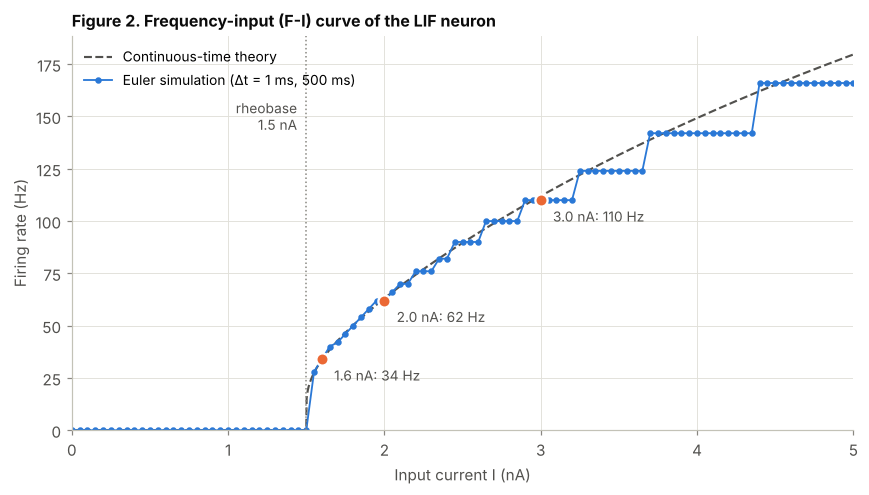

In [4]:
I_GRID = np.round(np.arange(0.0, 5.0 + 1e-9, 0.05), 2)
rates = np.array([firing_rate(simulate_lif(i, DURATION)[2], DURATION) for i in I_GRID])
rates_theory = lif_rate_theory(I_GRID)

i_rh = (LIF.v_th - LIF.e_l) / LIF.r_m
first_firing = I_GRID[np.argmax(rates > 0)]
print(f"Rheobase (theory): {i_rh:.2f} nA")
print(f"Lowest simulated current that fires: {first_firing:.2f} nA "
      f"(highest silent current: {I_GRID[rates == 0].max():.2f} nA)")
for i in (1.55, 2.0, 3.0, 4.0, 5.0):
    k = np.flatnonzero(np.isclose(I_GRID, i))[0]
    print(f"  I = {i:4.2f} nA: simulated {rates[k]:6.1f} Hz, continuous theory {rates_theory[k]:6.1f} Hz")

fine = np.linspace(0, 5, 2001)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(fine, lif_rate_theory(fine), "--", color=INK_2, lw=1.4, label="Continuous-time theory")
ax.plot(I_GRID, rates, "-o", color=BLUE, ms=3.2, lw=1.2, label="Euler simulation (Δt = 1 ms, 500 ms)")
for i in CURRENTS:
    r = firing_rate(runs[i][2], DURATION)
    ax.plot(i, r, "o", ms=8, color=ORANGE, mec="white", mew=1.5, zorder=5)
    ax.annotate(f"{i:.1f} nA: {r:.0f} Hz", (i, r), xytext=(8, -14), textcoords="offset points",
                color=INK_2, fontsize=9)
ax.axvline(i_rh, color=MUTED, lw=1, ls=":")
ax.annotate("rheobase\n1.5 nA", (i_rh, 150), xytext=(-6, 0), textcoords="offset points",
            ha="right", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("Input current I (nA)")
ax.set_ylabel("Firing rate (Hz)")
ax.set_xlim(0, 5)
ax.set_ylim(0, None)
ax.legend(loc="upper left")
ax.set_title("Figure 2. Frequency-input (F-I) curve of the LIF neuron", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_fi_curve.png")
plt.show()

**Checking the simulation exactly.** With constant input, the Euler update is a linear map
with closed-form solution
$V_j = V_\infty + (V_{reset} - V_\infty)(1 - \Delta t/\tau_m)^j$. The number of Euler steps
from reset to threshold is therefore

$$m = \left\lceil \frac{\ln\!\big[(V_\infty - V_{th}) / (V_\infty - V_{reset})\big]}{\ln(1 - \Delta t/\tau_m)} \right\rceil,$$

so the first spike comes at $m$ ms and every later ISI is $m + t_{ref}/\Delta t$ steps.
The cell below checks that the simulated spike count matches this prediction at all 101
currents.

In [5]:
def euler_spike_count(i_ext, duration=DURATION, params=LIF, dt=DT):
    """Spike count predicted by the closed-form solution of the Euler map (no simulation)."""
    v_inf = params.e_l + params.r_m * i_ext
    if v_inf <= params.v_th:
        return 0
    m = int(np.ceil(np.log((v_inf - params.v_th) / (v_inf - params.v_reset))
                    / np.log(1 - dt / params.tau_m)))
    n_steps = int(round(duration / dt))
    period = m + int(round(params.t_ref / dt))
    return 0 if m > n_steps else 1 + (n_steps - m) // period


predicted = np.array([euler_spike_count(i) for i in I_GRID])
simulated = np.round(rates * DURATION / 1000).astype(int)
assert np.array_equal(predicted, simulated), "simulation disagrees with the Euler closed form"
print(f"Spike counts match the closed-form Euler prediction at all {len(I_GRID)} currents.")

Spike counts match the closed-form Euler prediction at all 101 currents.


**Interpretation of the F-I curve.**

* **Threshold (rheobase).** The rate is exactly 0 Hz for every $I \le 1.5$ nA, because
  $V_\infty \le V_{th}$ and the voltage never reaches threshold. The simulation agrees: the
  last silent current is 1.50 nA and the first firing current is 1.55 nA.
* **Steep onset.** Just above rheobase the rate jumps straight to about 28 Hz rather than
  rising from zero. In theory the ISI diverges only logarithmically, as
  $\tau_m \ln[\ldots]$, so the rate rises very steeply near $I_{rh}$. With only 500 ms of
  simulation, rates below 2 Hz cannot be resolved at all.
* **Concave growth and saturation.** For large $I$ the rate grows sublinearly. It is bounded
  by the refractory period: $f \to 1/t_{ref} = 500$ Hz as $I \to \infty$.
* **Effect of Δt = 1 ms.** The simulated curve is a staircase because spike times are
  whole numbers of milliseconds, and the count over 500 ms is quantised to 2 Hz steps. Two
  discretisation errors partly cancel. The Euler factor $(1 - 0.1) = 0.900$ decays faster
  than the exact $e^{-0.1} = 0.905$, which makes firing early. Rounding the crossing up to
  the next step makes firing late. The net result is that the simulation stays within a few
  percent of the continuous curve at moderate currents and falls below it at high currents,
  where a single step is a large fraction of the ISI.

## Part 3: Two-neuron pair with STDP

### Learning rule

Let $\Delta t = t_{post} - t_{pre}$. The pair-based STDP window, with *separate* exponential
time constants for potentiation and depression, is

$$\Delta w(\Delta t) = \begin{cases} +A_+\, e^{-\Delta t/\tau_+} & \Delta t > 0 \quad \text{(pre before post: LTP)} \\ -A_-\, e^{\,\Delta t/\tau_-} & \Delta t < 0 \quad \text{(post before pre: LTD)} \\ 0 & \Delta t = 0 \end{cases}$$

| Symbol | Value | Reason |
|---|---|---|
| $\tau_+$ | 16.8 ms | fit to hippocampal pairing data (Bi & Poo, 1998; fit from Bi & Poo, 2001) |
| $\tau_-$ | 33.7 ms | same fit; the depression window is about twice as wide |
| $A_+$ | 0.010 | peak potentiation |
| $A_-$ | 0.006 | peak depression, smaller than $A_+$ as in the data |

With these values $A_-\tau_- = 0.202 > A_+\tau_+ = 0.168$, so the window's total area is
negative. Song, Miller & Abbott (2000) showed this net depression is needed for stable,
competitive learning with uncorrelated inputs.

### Implementation

* **Two LIF neurons** (the `LIFNeuron` class from Part 1, Euler with Δt = 1 ms), connected
  pre → post by an excitatory current-based synapse:
  $I_{syn} = g_{max}\, w\, s(t)$, where $s$ jumps by 1 at each presynaptic spike and decays
  with $\tau_{syn} = 5$ ms. With $g_{max} = 2$ nA and $w = 0.5$ the EPSP is about 2.5 mV,
  well below threshold, so the synapse does not change the post spike time.
* **Spike timing is controlled** as in a slice pairing experiment: each neuron gets a single
  20 nA, 1-ms current pulse, which drives it over threshold in exactly one Euler step.
* **Online, local STDP using eligibility traces.** A presynaptic trace $x$ decays with
  $\tau_+$ and a postsynaptic trace $y$ decays with $\tau_-$. On a post spike,
  $w \mathrel{+}= A_+ x$; on a pre spike, $w \mathrel{-}= A_- y$; after each update the
  spiking neuron's trace is incremented by 1. For an isolated spike pair this reproduces the
  exponential window exactly. The traces decay by the exact factor
  $e^{-\Delta t/\tau}$ each step, so they add no discretisation error. Weights are
  clipped to $[0, 1]$.
* Weight updates use only traces from *earlier* spikes, so coincident spikes
  ($\Delta t = 0$) give $\Delta w = 0$, matching the rule above.

In [6]:
@dataclass(frozen=True)
class STDPParams:
    a_plus: float = 0.010
    tau_plus: float = 16.8   # ms
    a_minus: float = 0.006
    tau_minus: float = 33.7  # ms
    w_min: float = 0.0
    w_max: float = 1.0


@dataclass(frozen=True)
class SynapseParams:
    g_max: float = 2.0       # nA delivered when w = 1 and s = 1
    tau_syn: float = 5.0     # ms


STDP = STDPParams()
SYN = SynapseParams()
W0 = 0.5          # initial weight at the start of every trial
PULSE = 20.0      # nA, 1-ms pulse that makes a neuron fire on the next step
T_FIRST = 20.0    # ms, time of the earlier of the two spikes
TRIAL = 100.0     # ms per trial (the later spike is at most 70 ms)


def stdp_window(delta_t, p=STDP):
    """Analytic STDP window: weight change for delta_t = t_post - t_pre (ms)."""
    delta_t = np.asarray(delta_t, dtype=float)
    ltp = p.a_plus * np.exp(-np.abs(delta_t) / p.tau_plus)
    ltd = -p.a_minus * np.exp(-np.abs(delta_t) / p.tau_minus)
    return np.where(delta_t > 0, ltp, np.where(delta_t < 0, ltd, 0.0))


@dataclass
class PairResult:
    delta_t: float            # realised t_post - t_pre (ms)
    dw: float                 # weight change over the trial
    t_pre: float
    t_post: float
    trace: dict | None = None  # time series, only when record=True


def simulate_pair(delta_t, w0=W0, lif=LIF, stdp=STDP, syn=SYN, dt=DT, record=False):
    """One pairing trial: pre and post each fire once, with post lagging pre by ~delta_t ms.

    delta_t is rounded to the dt grid, since spikes can only occur at multiples of dt.
    """
    shift = int(round(delta_t / dt))
    k_first = int(round(T_FIRST / dt))
    k_pre = k_first + max(0, -shift)      # target spike step of each neuron
    k_post = k_first + max(0, shift)
    n_steps = int(round(TRIAL / dt))

    pre, post = LIFNeuron(lif, dt), LIFNeuron(lif, dt)
    decay_plus = np.exp(-dt / stdp.tau_plus)
    decay_minus = np.exp(-dt / stdp.tau_minus)
    decay_syn = np.exp(-dt / syn.tau_syn)
    x_pre = y_post = s = 0.0
    w = w0
    pre_spikes, post_spikes = [], []

    if record:
        rec = {key: np.empty(n_steps + 1) for key in ("v_pre", "v_post", "x_pre", "y_post", "w")}
        rec["t"] = np.arange(n_steps + 1) * dt
        rec["v_pre"][0], rec["v_post"][0], rec["x_pre"][0], rec["y_post"][0], rec["w"][0] = (
            pre.v, post.v, x_pre, y_post, w)

    for n in range(n_steps):
        t_next = (n + 1) * dt
        # A pulse during step n makes the neuron cross threshold at t_{n+1} (the target time).
        i_pre = PULSE if n == k_pre - 1 else 0.0
        i_post = (PULSE if n == k_post - 1 else 0.0) + syn.g_max * w * s
        pre_fired = pre.step(i_pre)
        post_fired = post.step(i_post)

        # Exponential traces decay over the step (exact solution of dx/dt = -x / tau).
        x_pre *= decay_plus
        y_post *= decay_minus
        s *= decay_syn

        # STDP: each spike reads the *other* neuron's trace from its earlier spikes.
        if post_fired:
            w += stdp.a_plus * x_pre          # pre-before-post -> potentiation
            post_spikes.append(t_next)
        if pre_fired:
            w -= stdp.a_minus * y_post        # post-before-pre -> depression
            pre_spikes.append(t_next)
        w = min(max(w, stdp.w_min), stdp.w_max)

        # Only now add this step's spikes to the traces (and to the synaptic gate).
        if pre_fired:
            x_pre += 1.0
            s += 1.0
        if post_fired:
            y_post += 1.0

        if record:
            rec["v_pre"][n + 1], rec["v_post"][n + 1] = pre.v, post.v
            rec["x_pre"][n + 1], rec["y_post"][n + 1], rec["w"][n + 1] = x_pre, y_post, w

    if len(pre_spikes) != 1 or len(post_spikes) != 1:
        raise RuntimeError(f"expected one spike per neuron, got {len(pre_spikes)} pre and "
                           f"{len(post_spikes)} post")
    return PairResult(delta_t=post_spikes[0] - pre_spikes[0], dw=w - w0,
                      t_pre=pre_spikes[0], t_post=post_spikes[0],
                      trace=rec if record else None)

### 3a. What happens in a single trial

Two example trials: in the left column the pre neuron fires 10 ms *before* the post neuron
($\Delta t = +10$ ms); in the right column it fires 10 ms *after* ($\Delta t = -10$ ms).
The rows show the membrane voltages, the two STDP traces and the synaptic weight.

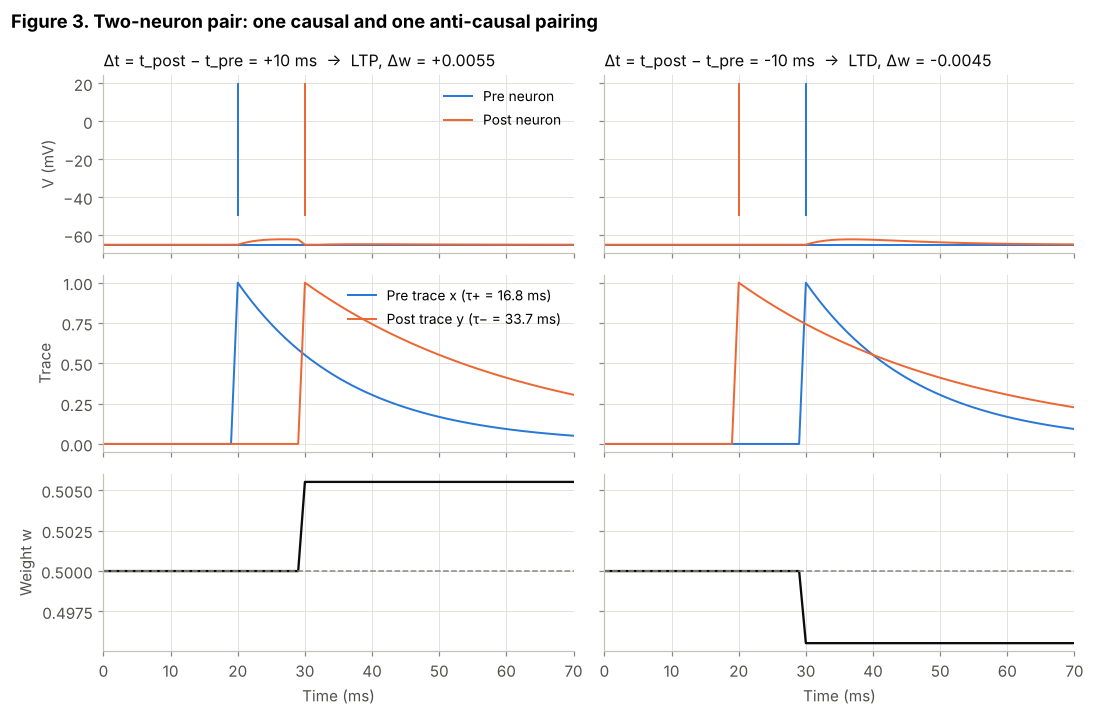

Δt = +10 ms: Δw = +0.005514 (analytic window: +0.005514)
Δt = -10 ms: Δw = -0.004459 (analytic window: -0.004459)


In [7]:
examples = [simulate_pair(+10, record=True), simulate_pair(-10, record=True)]

fig, axes = plt.subplots(3, 2, figsize=(10, 6.6), sharex=True, sharey="row")
for col, res in enumerate(examples):
    tr = res.trace
    kind = "LTP" if res.dw > 0 else "LTD"
    ax = axes[0, col]
    ax.plot(tr["t"], tr["v_pre"], color=BLUE, lw=1.3, label="Pre neuron")
    ax.plot(tr["t"], tr["v_post"], color=ORANGE, lw=1.3, label="Post neuron")
    ax.vlines(res.t_pre, LIF.v_th, V_PEAK, color=BLUE, lw=1.3)
    ax.vlines(res.t_post, LIF.v_th, V_PEAK, color=ORANGE, lw=1.3)
    ax.set_title(f"Δt = t_post − t_pre = {res.delta_t:+.0f} ms  →  {kind}, Δw = {res.dw:+.4f}")
    ax = axes[1, col]
    ax.plot(tr["t"], tr["x_pre"], color=BLUE, lw=1.3, label="Pre trace x (τ+ = 16.8 ms)")
    ax.plot(tr["t"], tr["y_post"], color=ORANGE, lw=1.3, label="Post trace y (τ− = 33.7 ms)")
    ax = axes[2, col]
    ax.plot(tr["t"], tr["w"], color=INK, lw=1.5)
    ax.axhline(W0, color=MUTED, lw=1, ls="--")
    ax.set_xlabel("Time (ms)")
axes[0, 0].set_ylabel("V (mV)")
axes[1, 0].set_ylabel("Trace")
axes[2, 0].set_ylabel("Weight w")
axes[0, 0].legend(loc="upper right")
axes[1, 0].legend(loc="upper right")
axes[0, 0].set_xlim(0, 70)
fig.suptitle("Figure 3. Two-neuron pair: one causal and one anti-causal pairing",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_stdp_example_pair.png")
plt.show()

for res in examples:
    print(f"Δt = {res.delta_t:+.0f} ms: Δw = {res.dw:+.6f} "
          f"(analytic window: {float(stdp_window(res.delta_t)):+.6f})")

In the causal trial (left), the post spike reads the pre trace $x$, which has decayed to
$e^{-10/16.8} = 0.55$, so $\Delta w = +0.010 \times 0.55 = +0.0055$. In the anti-causal
trial (right), the pre spike reads the post trace $y = e^{-10/33.7} = 0.74$, so
$\Delta w = -0.006 \times 0.74 = -0.0045$. The small bumps in the post voltage are the EPSPs
from the synapse, which are far below threshold.

### 3b. 1000 trials with random spike timing

In each trial I draw $\Delta t \sim \mathcal{U}(-50, +50)$ ms and run a fresh pair from
$w_0 = 0.5$. The weight change is recorded. With a 1 ms time step, spikes can only occur on
the 1 ms grid, so the realised $\Delta t$ is the draw rounded to the nearest millisecond.
To get the mean $\Delta w$ as a function of $\Delta t$, trials are grouped into 5 ms bins.
The bins never cross $\Delta t = 0$, so the jump between LTD and LTP is not averaged away.

In [8]:
N_TRIALS = 1000
rng = np.random.default_rng(SEED)
drawn = rng.uniform(-50.0, 50.0, N_TRIALS)
trials = [simulate_pair(d) for d in drawn]
delta_t = np.array([r.delta_t for r in trials])
dw = np.array([r.dw for r in trials])

assert np.all(np.abs(delta_t - drawn) <= 0.5 * DT + 1e-9), "realised timing must equal rounded draw"
print(f"{N_TRIALS} trials: {np.sum(delta_t > 0)} causal (Δt > 0), {np.sum(delta_t < 0)} "
      f"anti-causal (Δt < 0), {np.sum(delta_t == 0)} coincident (Δt = 0)")
print(f"Realised Δt range: {delta_t.min():.0f} to {delta_t.max():.0f} ms")


def binned_mean_sem(delta_t, dw, width=5.0, limit=50.0):
    """Mean and SEM of dw in delta_t bins. Negative bins are [lo, hi), positive bins
    are (lo, hi], and delta_t = 0 is excluded, so no bin crosses zero."""
    edges = np.arange(-limit, limit + width / 2, width)
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (delta_t >= lo) & (delta_t < hi) if hi <= 0 else (delta_t > lo) & (delta_t <= hi)
        if m.sum() < 2:
            continue
        out.append((delta_t[m].mean(), dw[m].mean(), dw[m].std(ddof=1) / np.sqrt(m.sum()), m.sum()))
    centre, mean, sem, count = np.array(out).T
    return centre, mean, sem, count.astype(int)


centre, mean_dw, sem_dw, count = binned_mean_sem(delta_t, dw)
print(f"\n{'bin centre (ms)':>15} {'n':>4} {'mean Δw':>10} {'SEM':>9}")
for c, m, s, n in zip(centre, mean_dw, sem_dw, count):
    print(f"{c:15.1f} {n:4d} {m:+10.5f} {s:9.5f}")

1000 trials: 504 causal (Δt > 0), 490 anti-causal (Δt < 0), 6 coincident (Δt = 0)
Realised Δt range: -50 to 50 ms

bin centre (ms)    n    mean Δw       SEM
          -47.9   38   -0.00145   0.00001
          -42.8   52   -0.00169   0.00001
          -38.2   44   -0.00193   0.00001
          -32.9   56   -0.00226   0.00001
          -28.3   47   -0.00260   0.00002
          -23.2   46   -0.00302   0.00002
          -18.0   45   -0.00352   0.00002
          -13.3   65   -0.00405   0.00002
           -8.1   53   -0.00472   0.00003
           -3.0   44   -0.00550   0.00004
            3.2   55   +0.00828   0.00010
            8.0   60   +0.00625   0.00007
           12.7   45   +0.00471   0.00006
           18.1   47   +0.00342   0.00004
           23.1   41   +0.00253   0.00003
           28.1   46   +0.00188   0.00002
           33.0   57   +0.00141   0.00002
           38.0   61   +0.00104   0.00001
           42.9   53   +0.00078   0.00001
           47.8   39   +0.00058   0.00001


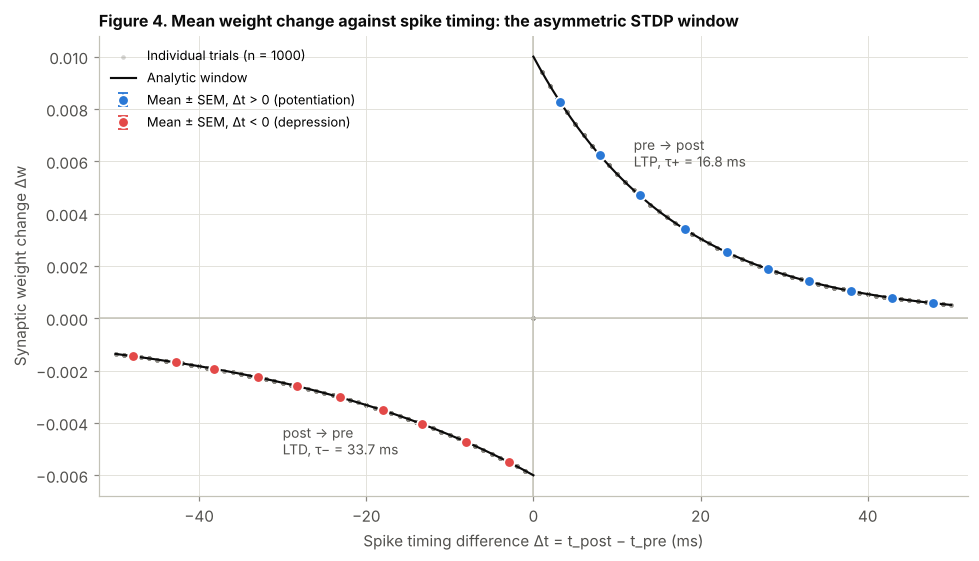

In [9]:
curve_neg = np.linspace(-50, -1e-6, 400)
curve_pos = np.linspace(1e-6, 50, 400)
ltp_bins, ltd_bins = centre > 0, centre < 0

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.axhline(0, color=AXIS, lw=1)
ax.axvline(0, color=AXIS, lw=1)
ax.scatter(delta_t, dw, s=9, color=MUTED, alpha=0.35, lw=0, label=f"Individual trials (n = {N_TRIALS})")
ax.plot(curve_pos, stdp_window(curve_pos), color=INK, lw=1.4, label="Analytic window")
ax.plot(curve_neg, stdp_window(curve_neg), color=INK, lw=1.4)
ax.errorbar(centre[ltp_bins], mean_dw[ltp_bins], yerr=sem_dw[ltp_bins], fmt="o", ms=7,
            color=BLUE, mec="white", mew=1.2, capsize=3, elinewidth=1.2,
            label="Mean ± SEM, Δt > 0 (potentiation)")
ax.errorbar(centre[ltd_bins], mean_dw[ltd_bins], yerr=sem_dw[ltd_bins], fmt="o", ms=7,
            color=RED, mec="white", mew=1.2, capsize=3, elinewidth=1.2,
            label="Mean ± SEM, Δt < 0 (depression)")
ax.annotate("pre → post\nLTP, τ+ = 16.8 ms", (12, 0.0058), color=INK_2, fontsize=9)
ax.annotate("post → pre\nLTD, τ− = 33.7 ms", (-30, -0.0052), color=INK_2, fontsize=9)
ax.set_xlabel("Spike timing difference Δt = t_post − t_pre (ms)")
ax.set_ylabel("Synaptic weight change Δw")
ax.set_xlim(-52, 52)
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Figure 4. Mean weight change against spike timing: the asymmetric STDP window",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_stdp_window.png")
plt.show()

### 3c. Verifying the asymmetric STDP window

The checks below confirm that the simulated pair has every feature of the characteristic
window. Each is an `assert`, so the notebook stops if any of them fails.

1. **Sign follows causality:** every causal pairing potentiates and every anti-causal
   pairing depresses.
2. **Exponential shape with the right time constants:** a straight-line fit of
   $\ln|\Delta w|$ against $\Delta t$ on each side recovers $A_\pm$ and $\tau_\pm$.
3. **Asymmetry:** the LTD side is wider ($\tau_- > \tau_+$), the LTP side is taller
   ($A_+ > A_-$), and there is a jump at $\Delta t = 0$ from $-A_-$ to $+A_+$.
4. **Decay toward zero:** pairings 50 ms apart produce little change.
5. **Matches the analytic rule** trial by trial.

In [10]:
def fit_window(delta_t, dw):
    """Fit A * exp(-|dt| / tau) to each side of the window by linear regression on log|dw|."""
    pos, neg = delta_t > 0, delta_t < 0
    slope_p, icept_p = np.polyfit(delta_t[pos], np.log(dw[pos]), 1)
    slope_n, icept_n = np.polyfit(delta_t[neg], np.log(-dw[neg]), 1)
    return {"a_plus": np.exp(icept_p), "tau_plus": -1 / slope_p,
            "a_minus": np.exp(icept_n), "tau_minus": 1 / slope_n}


causal, anti = delta_t > 0, delta_t < 0
fit = fit_window(delta_t, dw)
max_err = np.max(np.abs(dw - stdp_window(delta_t)))
nearest_ltp = dw[delta_t == delta_t[causal].min()].mean()      # Δt = +1 ms
nearest_ltd = dw[delta_t == delta_t[anti].max()].mean()        # Δt = -1 ms
far_ratio = np.abs(stdp_window([50, -50])) / np.array([STDP.a_plus, STDP.a_minus])

checks = [
    ("All causal pairings potentiate (Δw > 0)", np.all(dw[causal] > 0),
     f"{causal.sum()} trials, min Δw = {dw[causal].min():+.5f}"),
    ("All anti-causal pairings depress (Δw < 0)", np.all(dw[anti] < 0),
     f"{anti.sum()} trials, max Δw = {dw[anti].max():+.5f}"),
    ("Fitted τ+ matches 16.8 ms", np.isclose(fit["tau_plus"], STDP.tau_plus, rtol=1e-3),
     f"τ+ = {fit['tau_plus']:.3f} ms"),
    ("Fitted τ− matches 33.7 ms", np.isclose(fit["tau_minus"], STDP.tau_minus, rtol=1e-3),
     f"τ− = {fit['tau_minus']:.3f} ms"),
    ("Fitted A+ and A− match 0.010 and 0.006",
     np.isclose(fit["a_plus"], STDP.a_plus, rtol=1e-3) and np.isclose(fit["a_minus"], STDP.a_minus, rtol=1e-3),
     f"A+ = {fit['a_plus']:.5f}, A− = {fit['a_minus']:.5f}"),
    ("Asymmetric widths: depression window wider (τ− > τ+)", fit["tau_minus"] > fit["tau_plus"],
     f"τ−/τ+ = {fit['tau_minus'] / fit['tau_plus']:.2f}"),
    ("Asymmetric heights: peak LTP larger than peak LTD", fit["a_plus"] > fit["a_minus"],
     f"A+/A− = {fit['a_plus'] / fit['a_minus']:.2f}"),
    ("Sharp jump at Δt = 0 (−1 ms vs +1 ms)", nearest_ltd < 0 < nearest_ltp,
     f"Δw(−1) = {nearest_ltd:+.5f}, Δw(+1) = {nearest_ltp:+.5f}"),
    ("|Δw| at ±50 ms has decayed to < 25 % of the peak", np.all(far_ratio < 0.25),
     f"LTP {far_ratio[0]:.1%}, LTD {far_ratio[1]:.1%} of peak"),
    ("Every trial equals the analytic window", max_err < 1e-12,
     f"max |Δw_sim − Δw_rule| = {max_err:.1e}"),
]

width = max(len(name) for name, _, _ in checks)
for name, ok, detail in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {name:<{width}}  {detail}")
assert all(ok for _, ok, _ in checks), "STDP window verification failed"
print("\nAll checks passed: the simulation reproduces the asymmetric STDP window.")

[PASS] All causal pairings potentiate (Δw > 0)               504 trials, min Δw = +0.00051
[PASS] All anti-causal pairings depress (Δw < 0)             490 trials, max Δw = -0.00136
[PASS] Fitted τ+ matches 16.8 ms                             τ+ = 16.800 ms
[PASS] Fitted τ− matches 33.7 ms                             τ− = 33.700 ms
[PASS] Fitted A+ and A− match 0.010 and 0.006                A+ = 0.01000, A− = 0.00600
[PASS] Asymmetric widths: depression window wider (τ− > τ+)  τ−/τ+ = 2.01
[PASS] Asymmetric heights: peak LTP larger than peak LTD     A+/A− = 1.67
[PASS] Sharp jump at Δt = 0 (−1 ms vs +1 ms)                 Δw(−1) = -0.00582, Δw(+1) = +0.00942
[PASS] |Δw| at ±50 ms has decayed to < 25 % of the peak      LTP 5.1%, LTD 22.7% of peak
[PASS] Every trial equals the analytic window                max |Δw_sim − Δw_rule| = 5.4e-17

All checks passed: the simulation reproduces the asymmetric STDP window.


### 3d. Net effect of random timing

Averaged over the full ±50 ms range, the expected weight change per pairing is

$$\mathbb{E}[\Delta w] = \frac{1}{100}\Big[A_+\tau_+\big(1 - e^{-50/\tau_+}\big) - A_-\tau_-\big(1 - e^{-50/\tau_-}\big)\Big].$$

In [11]:
expected = (STDP.a_plus * STDP.tau_plus * (1 - np.exp(-50 / STDP.tau_plus))
            - STDP.a_minus * STDP.tau_minus * (1 - np.exp(-50 / STDP.tau_minus))) / 100
print(f"Mean Δw over all {N_TRIALS} trials: {dw.mean():+.6f} ± {dw.std(ddof=1) / np.sqrt(N_TRIALS):.6f} (SEM)")
print(f"Expected value for Δt ~ U(-50, 50):  {expected:+.6f}")
print(f"Whole-window integral: A+τ+ = {STDP.a_plus * STDP.tau_plus:.3f} ms, "
      f"A−τ− = {STDP.a_minus * STDP.tau_minus:.3f} ms (net depressing)")

Mean Δw over all 1000 trials: +0.000072 ± 0.000118 (SEM)
Expected value for Δt ~ U(-50, 50):  +0.000031
Whole-window integral: A+τ+ = 0.168 ms, A−τ− = 0.202 ms (net depressing)


Within ±50 ms, potentiation and depression almost cancel. The expected change is only about
$+3 \times 10^{-5}$ per pairing, and the simulated mean is consistent with it within its
standard error. Over the whole window, though, the depression lobe is larger
($A_-\tau_- > A_+\tau_+$). Uncorrelated pre and post firing therefore weakens a synapse on
average, and only inputs that consistently fire *just before* the postsynaptic cell are
strengthened.

## Conclusions

1. **LIF dynamics.** The Euler-integrated LIF neuron charges exponentially toward
   $E_L + R_m I$ and fires regularly once that value exceeds threshold. Stronger input
   shortens the ISI: 29 ms, 16 ms and 9 ms at 1.6, 2.0 and 3.0 nA.
2. **F-I curve.** The neuron is silent below the 1.5 nA rheobase, turns on abruptly just
   above it, and then increases its rate sublinearly toward the refractory limit of 500 Hz.
   The simulated spike counts match the closed-form solution of the Euler map exactly.
   They stay within a few percent of the continuous-time theory at moderate currents; the
   remaining gap comes from Δt = 1 ms being a sizeable fraction of a short ISI.
3. **STDP.** Over 1000 random-timing trials, the two-neuron pair reproduces the
   characteristic asymmetric window. Pre-before-post pairings potentiate and
   post-before-pre pairings depress, with a sharp sign change at $\Delta t = 0$. The LTP
   lobe is taller ($A_+ = 0.010$ vs $A_- = 0.006$) but narrower ($\tau_+ = 16.8$ ms vs
   $\tau_- = 33.7$ ms). Fitting the simulated data recovers all four parameters.
4. **Limitations.** The rule is pair-based and additive. It ignores triplet and
   firing-rate effects, weight-dependent (multiplicative) updates and dendritic location.
   Because spike timing is set directly by current pulses, the trial-to-trial spread within
   a bin comes only from the spread of $\Delta t$ inside the bin. Biological measurements
   show much more variability.

**References**

* Bi, G. Q. & Poo, M. M. (1998). Synaptic modifications in cultured hippocampal neurons:
  dependence on spike timing, synaptic strength, and postsynaptic cell type.
  *J. Neurosci.* 18(24), 10464–10472.
* Bi, G. Q. & Poo, M. M. (2001). Synaptic modification by correlated activity: Hebb's
  postulate revisited. *Annu. Rev. Neurosci.* 24, 139–166.
* Song, S., Miller, K. D. & Abbott, L. F. (2000). Competitive Hebbian learning through
  spike-timing-dependent synaptic plasticity. *Nat. Neurosci.* 3(9), 919–926.
* Dayan, P. & Abbott, L. F. (2001). *Theoretical Neuroscience*, ch. 5 and 8. MIT Press.